# AirSense - 04 Drift Monitoring Demo
The backend keeps a rolling window of the last 200 user-supplied readings per pollutant and exports
`drift z-score = (rolling mean - training mean) / training std` to Prometheus (`airsense_input_drift_zscore`).
Grafana plots it and the `InputDrift` alert fires when |z| > 0.5 for 2 minutes (see `alert_rules.yml`).

This notebook **simulates a regime change**: 200 normal requests, then 200 requests where PM2.5 and PM10 are 2.5x higher (e.g. a sensor fault or a pollution season the model never saw), and watches the gauge react.

> For a clean baseline, **restart the API** before running this notebook (the window is kept in memory).

In [1]:
import os, re, json
import requests
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

API_URL = os.getenv("API_URL", "http://localhost:8000")
meta = json.load(open("models/model_meta.json"))
test = pd.read_csv("data/processed/test.csv")
test = test[test.City.isin(meta["cities"])]  # API only knows trained cities
rng = np.random.default_rng(7)

def gauge(feature):
    text = requests.get(f"{API_URL}/metrics").text
    m = re.search(rf'airsense_input_drift_zscore{{feature="{re.escape(feature)}"}} (\S+)', text)
    return float(m.group(1)) if m else np.nan

print("training mean/std  PM2.5:", round(meta["feature_mean"]["PM2.5"], 1), "/", round(meta["feature_std"]["PM2.5"], 1),
      "| PM10:", round(meta["feature_mean"]["PM10"], 1), "/", round(meta["feature_std"]["PM10"], 1))

training mean/std  PM2.5: 76.5 / 66.6 | PM10: 125.8 / 82.8


## 1. Send traffic: normal first, then shifted

In [2]:
def send(row, scale=1.0):
    payload = {"city": row["City"], "pm25": float(row["PM2.5"]) * scale, "pm10": float(row["PM10"]) * scale, "no2": float(row["NO2"])}
    payload["pm25"] = min(payload["pm25"], 1000); payload["pm10"] = min(payload["pm10"], 2000)
    return requests.post(f"{API_URL}/predict", json=payload).status_code

N = 200
sample = test.sample(2 * N, random_state=7).to_dict("records")
trace, step = [], 0
for phase, scale, rows in [("normal", 1.0, sample[:N]), ("shifted x2.5", 2.5, sample[N:])]:
    for i, row in enumerate(rows, 1):
        assert send(row, scale) == 200
        step += 1
        if step % 10 == 0:
            trace.append({"request": step, "phase": phase, "PM2.5 z": gauge("PM2.5"), "PM10 z": gauge("PM10"), "NO2 z": gauge("NO2")})
trace = pd.DataFrame(trace)
trace.tail(6)

,request,phase,PM2.5 z,PM10 z,NO2 z
34,350,shifted x2.5,0.296555,0.667995,-0.179925
35,360,shifted x2.5,0.386808,0.799615,-0.211235
36,370,shifted x2.5,0.480845,0.925072,-0.179027
37,380,shifted x2.5,0.553053,0.991641,-0.188709
38,390,shifted x2.5,0.625482,1.065296,-0.220664
39,400,shifted x2.5,0.631746,1.109691,-0.190211


## 2. Watch the drift gauge react

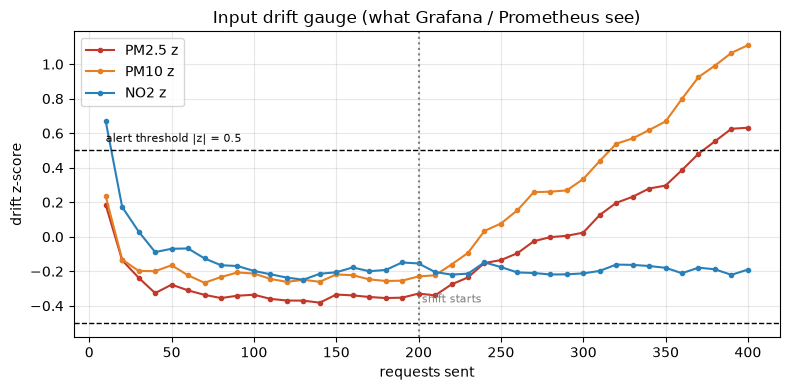

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
for col, c in [("PM2.5 z", "#C0392B"), ("PM10 z", "#E67E22"), ("NO2 z", "#2980B9")]:
    ax.plot(trace["request"], trace[col], marker="o", ms=3, label=col, color=c)
ax.axhline(0.5, ls="--", color="k", lw=1); ax.axhline(-0.5, ls="--", color="k", lw=1)
ax.text(trace["request"].min(), 0.55, "alert threshold |z| = 0.5", fontsize=8)
ax.axvline(N, color="grey", ls=":"); ax.text(N + 2, ax.get_ylim()[0] + .2, "shift starts", fontsize=8, color="grey")
ax.set_xlabel("requests sent"); ax.set_ylabel("drift z-score"); ax.set_title("Input drift gauge (what Grafana / Prometheus see)")
ax.grid(alpha=.3); ax.legend(); plt.tight_layout(); plt.show()

In [4]:
end = trace.iloc[-1]; base = trace[trace.phase == "normal"].iloc[-1]
print(f"Before the shift (request {int(base['request'])}): PM2.5 z = {base['PM2.5 z']:+.2f}   PM10 z = {base['PM10 z']:+.2f}")
print(f"After  the shift (request {int(end['request'])}): PM2.5 z = {end['PM2.5 z']:+.2f}   PM10 z = {end['PM10 z']:+.2f}")
print("NO2 (unchanged feature) stays near", f"{end['NO2 z']:+.2f}", "- the gauge reacts only where the data really changed.")
fired = [c for c in ["PM2.5 z", "PM10 z"] if abs(end[c]) > 0.5]
print("Features beyond the |z| > 0.5 alert threshold:", fired or "none")

Before the shift (request 200): PM2.5 z = -0.33   PM10 z = -0.23
After  the shift (request 400): PM2.5 z = +0.63   PM10 z = +1.11
NO2 (unchanged feature) stays near -0.19 - the gauge reacts only where the data really changed.
Features beyond the |z| > 0.5 alert threshold: ['PM2.5 z', 'PM10 z']


## 3. Why the threshold is 0.5

z is measured in units of the training population standard deviation. For a skewed pollutant measured across 26 cities that standard deviation is large, so even a **2.5x jump in PM2.5 only moved z to about +0.6** on the real data. We therefore alert on a *medium* effect size, |z| > 0.5 (Cohen's-d convention: 0.2 small, 0.5 medium, 0.8 large), sustained for 2 minutes.

History of this setting, stated openly: **3** (initial guess, never fired) -> **1** (chosen on synthetic demo data) -> **0.5** (after real data showed a large shift staying below 1). The last two values were picked after seeing demo results, so revisit them with real production traffic.

Notes: the baseline is already near -0.3 because the 2019-2020 test period is cleaner than the training years, which is itself real drift between periods. The gauge measures *effect size*, not statistical significance; for the latter divide by sigma/sqrt(200), about 0.07.

## 4. What would happen in production
* Prometheus scrapes the gauge every 5 s; if |z| stays above 1 for 2 minutes the `InputDrift` alert fires.
* The response is **investigate, then retrain**: add the new data and run `dvc repro`; MLflow records the new run and the backend picks up the new model after a restart.
* Limits: this detects *input* shift only. Without ground-truth labels arriving later, production **accuracy** cannot be measured by this app.